In [1]:
import random
import numpy as np
import torch

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

# Usage
set_seed(42)

In [2]:
%load_ext autoreload
%autoreload 2
from lcb_no_forget import LCB, LCBModel
import os
from nets import ValueEstimate, LogUBaselineNet, train_val_estimate, load_val_estimate
from collection import Collector
run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)
alpha = 0.2

value_estimator_temp_0p2, states, index_set, _ = load_val_estimate(run_id, 0.2, device="mps", file_name = "value_net_temp_0p2_20_epochs")
value_estimator_temp_0p33, states, index_set, _ = load_val_estimate(run_id, 0.33, device="mps", file_name = "value_net_temp_0p33_20_epochs")
value_estimator_temp_1p0, states, index_set, _ = load_val_estimate(run_id, 1.0, device="mps", file_name = "value_net_temp_1p0_20_epochs")

collector = Collector(None, None)
core, states, expr = collector.load_collected(run_dir)
core.S = 7000
print("states shape:", states.shape)
in_dim = value_estimator_temp_0p2.in_dim

states shape: (20, 70000, 2)


In [3]:
import numpy as np

class RejectionSampling:
    """
    Simple rejection sampling policy analogous to LCBModel.lcb_step, but with
    acceptance probability:   p_accept = exp(v_t(x_t) - B)

    where v_t is provided in *log-space* by value_estimator.predict_under_log(...),
    and B is a user-chosen constant (typically >= max log v so p<=1 mostly).
    """
    def __init__(self, core, value_estimator, B: float, N: int = 5):
        self.core = core
        self.core.reset()
        self.value_estimator = value_estimator
        self.index_set = self.core.model_config["index_set"]
        self.B = float(B)
        self.N = int(N)

        self.S = self.core.S
        self.num_steps = 0  # total proposals used (like LCBModel.num_steps)

    def rs_step(self):
        """
        Perform one reverse-time step (t+1 -> t) using rejection sampling.
        Mirrors LCBModel.lcb_step structure.

        Returns:
            accepted_states: (S, d) np.ndarray
            num_proposals:   length-S list[int] proposals consumed per chain
        """
        tp1 = self.core.t  # current time index is "t+1" in their convention
        if tp1 < 0:
            raise ValueError(f"rs_step called with core.t={tp1}; expected t>=1 (so we can go to t-1).")

        Xtp1 = self.core.X  # (S, d)
        S = Xtp1.shape[0]

        # proposals per active chain per loop-iteration
        self.core.N = self.N

        active = list(range(S))
        accepted_states = [None] * S
        num_proposals = [0] * S

        # Loop until every chain accepts a proposal
        while active:
            # Propose candidates for currently-active indices.
            # Expected shape: (N, len(active), d)
            Xt = self.core.propose_external(Xtp1[active], tp1, N=self.core.N)

            # log v_t for each proposed state at time t = tp1-1
            # expected shape: (N, len(active))
            logvt = self.value_estimator.predict_under_log(Xt, self.index_set[tp1 - 1])

            acc = np.exp(logvt - self.B)
            acc = np.clip(acc, 0.0, 1.0)

            u = np.random.rand(*acc.shape)

            # Ensure acc is shaped (A, N): rows = active chains, cols = proposals
            # A = len(active), N = self.core.N
            A = len(active)
            N = self.core.N
            if acc.shape == (N, A):
                acc = acc.T
                u = u.T
            elif acc.shape != (A, N):
                raise ValueError(f"Unexpected acc shape {acc.shape}; expected {(A, N)} or {(N, A)}")

            new_active = []
            for j, orig_idx in enumerate(active):
                ok = np.where(acc[j, :] > u[j, :])[0]
                if ok.size:
                    first = int(ok[0])
                    # Xt could be (N, A, d) or (A, N, d) depending on Core; handle both.
                    if Xt.shape[:2] == (N, A):
                        accepted_states[orig_idx] = Xt[first, j]
                    elif Xt.shape[:2] == (A, N):
                        accepted_states[orig_idx] = Xt[j, first]
                    else:
                        raise ValueError(f"Unexpected Xt shape {Xt.shape}; expected {(N, A, 'd')} or {(A, N, 'd')}")
                    num_proposals[orig_idx] += first + 1
                else:
                    new_active.append(orig_idx)
                    num_proposals[orig_idx] += N

            active = new_active


        accepted_states = np.stack(accepted_states, axis=0)
        self.core.commit(accepted_states)
        self.num_steps += int(sum(num_proposals))
        return accepted_states, num_proposals

    def set_S(self, S: int):
        self.core.S = int(S)
        self.S = int(S)
        self.core.reset()

    def calc_samples(self):
        """
        Roll out samples using rejection sampling, returning an array of shape (T+1, S, d),
        matching LCBModel.calc_samples().
        """
        self.core.reset()
        self.num_steps = 0

        # initial noisy state at time T
        init_props = self.core.propose()
        if init_props.ndim == 3:
            x_init = init_props[:, 0, :]
        else:
            x_init = init_props
        self.core.commit(x_init)

        T_plus_1 = self.core.T + 1
        d = x_init.shape[-1]
        states = np.empty((T_plus_1, self.S, d))
        states[self.core.t + 1] = x_init  # time index T

        while self.core.t >= 0:
            states_t, _ = self.rs_step()
            states[self.core.t] = states_t

        return states


rs_temp_0p2 = RejectionSampling(core=core, value_estimator=value_estimator_temp_0p2, B=1/0.2)
rs_temp_0p33 = RejectionSampling(core=core, value_estimator=value_estimator_temp_0p33, B=1/0.33)
rs_temp_1p0 = RejectionSampling(core=core, value_estimator=value_estimator_temp_1p0, B=1)

rs_temp_0p2.set_S(7000)
rs_temp_0p33.set_S(7000)
rs_temp_1p0.set_S(7000)

X_rs_temp_0p2 = rs_temp_0p2.calc_samples()
X_rs_temp_0p33 = rs_temp_0p33.calc_samples()
X_rs_temp_1p0 = rs_temp_1p0.calc_samples()
print("proposal per timestep ratio (temp = 0.2)", rs_temp_0p2.num_steps/(7000*20))
print("proposal per timestep ratio (temp = 0.33)", rs_temp_0p33.num_steps/(7000*20))
print("proposal per timestep ratio (temp = 1.0)", rs_temp_1p0.num_steps/(7000*20))


proposal per timestep ratio (temp = 0.2) 68.98592142857143
proposal per timestep ratio (temp = 0.33) 13.833235714285713
proposal per timestep ratio (temp = 1.0) 1.9533928571428572


In [4]:
Ns_temp0p2 = {}

lcb = LCB(
    2, 
    value_estimator_temp_0p2,
    core,
    delta = 0.1,
    fix_lambda=True,
    symmetric= True,
    lambda_value=1,
    lam_min=1,
    lam_max=2,
    erm_error=0.0,
    baseline_lr = 1e-4
)

model_temp_0p2 = LCBModel(core, lcb)
model_temp_0p2.num_train_steps_per_t = 200
model_temp_0p2.num_baseline_epochs_per_step = 1
X = model_temp_0p2.train()

print("effective N = ", model_temp_0p2.num_steps/(7000*20))

model_temp_0p2_delta_0p005 = model_temp_0p2
model_temp_0p2_delta_0p005.lcb.lam_max = 20
model_temp_0p2_delta_0p005.lcb.fix_lambda = False
model_temp_0p2_delta_0p005.lcb.delta = 0.005

model_temp_0p2_delta_0p005.num_train_steps_per_t = 1
model_temp_0p2_delta_0p005.num_steps = 0
X_temp_0p2_delta_0p005 = model_temp_0p2_delta_0p005.train()
print("effective N (delta=0.005) = ", model_temp_0p2_delta_0p005.num_steps/(7000*20))

Ns_temp0p2["delta_0p005"] = model_temp_0p2_delta_0p005.num_steps/(7000*20)

model_temp_0p2_delta_0p05 = model_temp_0p2
model_temp_0p2_delta_0p05.lcb.lam_max = 10
model_temp_0p2_delta_0p05.lcb.fix_lambda = False
model_temp_0p2_delta_0p05.lcb.delta = 0.05

model_temp_0p2_delta_0p05.num_train_steps_per_t = 1
model_temp_0p2_delta_0p05.num_steps = 0
X_temp_0p2_delta_0p05 = model_temp_0p2_delta_0p05.train()
print("effective N (delta=0.05) = ", model_temp_0p2_delta_0p05.num_steps/(7000*20))

Ns_temp0p2["delta_0p05"] = model_temp_0p2_delta_0p05.num_steps/(7000*20)

model_temp_0p2_delta_0p1 = model_temp_0p2
model_temp_0p2_delta_0p1.lcb.lam_max = 10
model_temp_0p2_delta_0p1.lcb.delta = 0.1
model_temp_0p2_delta_0p1.num_steps = 0
model_temp_0p2_delta_0p1.lcb.fix_lambda = False
model_temp_0p2_delta_0p1.num_train_steps_per_t = 1
X_temp_0p2_delta_0p1 = model_temp_0p2_delta_0p1.train()
print("effective N (delta=0.1) = ", model_temp_0p2_delta_0p1.num_steps/(7000*20))

Ns_temp0p2["delta_0p1"] = model_temp_0p2_delta_0p1.num_steps/(7000*20)

model_temp_0p2_delta_0p2 = model_temp_0p2
model_temp_0p2_delta_0p2.lcb.lam_max = 10
model_temp_0p2_delta_0p2.lcb.fix_lambda = False
model_temp_0p2_delta_0p2.lcb.delta = 0.2

model_temp_0p2_delta_0p2.num_train_steps_per_t = 1
model_temp_0p2_delta_0p2.num_steps = 0
X_temp_0p2_delta_0p2 = model_temp_0p2_delta_0p2.train()
print("effective N (delta=0.2) = ", model_temp_0p2_delta_0p2.num_steps/(7000*20))

Ns_temp0p2["delta_0p2"] = model_temp_0p2_delta_0p2.num_steps/(7000*20)

model_temp_0p2_delta_0p3 = model_temp_0p2
model_temp_0p2_delta_0p3.lcb.lam_max = 10
model_temp_0p2_delta_0p3.lcb.fix_lambda = False
model_temp_0p2_delta_0p3.lcb.delta = 0.3

model_temp_0p2_delta_0p3.num_train_steps_per_t = 1
model_temp_0p2_delta_0p3.num_steps = 0
X_temp_0p2_delta_0p3 = model_temp_0p2_delta_0p3.train()
print("effective N (delta=0.3) = ", model_temp_0p2_delta_0p3.num_steps/(7000*20))

Ns_temp0p2["delta_0p3"] = model_temp_0p2_delta_0p3.num_steps/(7000*20)


LCB Model has S =  7000
effective N =  13.930428571428571
effective N (delta=0.005) =  7.2240142857142855
effective N (delta=0.05) =  6.474407142857143
effective N (delta=0.1) =  5.516228571428571
effective N (delta=0.2) =  4.075342857142857
effective N (delta=0.3) =  3.286057142857143


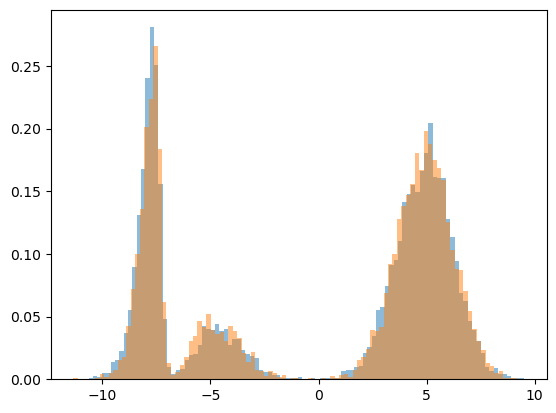

In [5]:
import matplotlib.pyplot as plt
plt.hist(X_rs_temp_0p2[0, :, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p2_delta_0p005[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p2_delta_0p05[:, 0], bins = 100, density=True, alpha=0.5)
plt.hist(X_temp_0p2_delta_0p1[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p2_delta_0p2[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p2_delta_0p3[:, 0], bins = 100, density=True, alpha=0.5)
plt.show()

In [6]:
%load_ext autoreload
%autoreload 2
from lcb_no_forget import LCB, LCBModel
import os
from nets import ValueEstimate, LogUBaselineNet, train_val_estimate, load_val_estimate
from collection import Collector
run_id = "20260122_202321_157606"
run_dir = os.path.join("toy_data_runs", run_id)
alpha = 0.33

set_seed(42)

value_estimator, states, index_set, _ = load_val_estimate(run_id, alpha, device="mps")
collector = Collector(None, None)
core, states, expr = collector.load_collected(run_dir)


core.S = 7000
print("states shape:", states.shape)
in_dim = value_estimator.in_dim

# Train LCB ################
    
Ns_temp0p33 = {}

lcb = LCB(
    2, 
    value_estimator_temp_0p33,
    core,
    delta = 0.1,
    fix_lambda=True,
    symmetric= True,
    lambda_value=1,
    lam_min=1,
    lam_max=2,
    erm_error=0.0,
    baseline_lr = 1e-4
)

model_temp_0p33 = LCBModel(core, lcb)
model_temp_0p33.num_train_steps_per_t = 200
model_temp_0p33.num_baseline_epochs_per_step = 1
X = model_temp_0p33.train()

print("effective N = ", model_temp_0p33.num_steps/(7000*20))


model_temp_0p33_delta_0p005 = model_temp_0p33
model_temp_0p33_delta_0p005.lcb.lam_max = 20
model_temp_0p33_delta_0p005.lcb.fix_lambda = False
model_temp_0p33_delta_0p005.lcb.delta = 0.005

model_temp_0p33_delta_0p005.num_train_steps_per_t = 1
model_temp_0p33_delta_0p005.num_steps = 0
X_temp_0p33_delta_0p005 = model_temp_0p33_delta_0p005.train()
print("effective N (temp=0.33, delta=0.005) = ", model_temp_0p33_delta_0p005.num_steps/(7000*20))
Ns_temp0p33["delta_0p005"] = model_temp_0p33_delta_0p005.num_steps/(7000*20)


model_temp_0p33_delta_0p05 = model_temp_0p33
model_temp_0p33_delta_0p05.lcb.lam_max = 10
model_temp_0p33_delta_0p05.lcb.fix_lambda = False
model_temp_0p33_delta_0p05.lcb.delta = 0.05

model_temp_0p33_delta_0p05.num_train_steps_per_t = 1
model_temp_0p33_delta_0p05.num_steps = 0
X_temp_0p33_delta_0p05 = model_temp_0p33_delta_0p05.train()
print("effective N (temp=0.33, delta=0.05) = ", model_temp_0p33_delta_0p05.num_steps/(7000*20))
Ns_temp0p33["delta_0p05"] = model_temp_0p33_delta_0p05.num_steps/(7000*20)

model_temp_0p33_delta_0p1 = model_temp_0p33
model_temp_0p33_delta_0p1.lcb.lam_max = 10
model_temp_0p33_delta_0p1.lcb.delta = 0.1
model_temp_0p33_delta_0p1.num_steps = 0
model_temp_0p33_delta_0p1.lcb.fix_lambda = False
model_temp_0p33_delta_0p1.num_train_steps_per_t = 1
X_temp_0p33_delta_0p1 = model_temp_0p33_delta_0p1.train()
print("effective N (temp=0.33, delta=0.1) = ", model_temp_0p33_delta_0p1.num_steps/(7000*20))
Ns_temp0p33["delta_0p1"] = model_temp_0p33_delta_0p1.num_steps/(7000*20)


model_temp_0p33_delta_0p2 = model_temp_0p33
model_temp_0p33_delta_0p2.lcb.lam_max = 10
model_temp_0p33_delta_0p2.lcb.fix_lambda = False
model_temp_0p33_delta_0p2.lcb.delta = 0.2

model_temp_0p33_delta_0p2.num_train_steps_per_t = 1
model_temp_0p33_delta_0p2.num_steps = 0
X_temp_0p33_delta_0p2 = model_temp_0p33_delta_0p2.train()
print("effective N (temp=0.33, delta=0.2) = ", model_temp_0p33_delta_0p2.num_steps/(7000*20))

Ns_temp0p33["delta_0p2"] = model_temp_0p33_delta_0p2.num_steps/(7000*20)

model_temp_0p33_delta_0p3 = model_temp_0p33
model_temp_0p33_delta_0p3.lcb.lam_max = 10
model_temp_0p33_delta_0p3.lcb.fix_lambda = False
model_temp_0p33_delta_0p3.lcb.delta = 0.3

model_temp_0p33_delta_0p3.num_train_steps_per_t = 1
model_temp_0p33_delta_0p3.num_steps = 0
X_temp_0p33_delta_0p3 = model_temp_0p33_delta_0p3.train()
print("effective N (temp=0.33, delta=0.3) = ", model_temp_0p33_delta_0p3.num_steps/(7000*20))

Ns_temp0p33["delta_0p3"] = model_temp_0p33_delta_0p3.num_steps/(7000*20)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
states shape: (20, 70000, 2)
LCB Model has S =  7000
effective N =  9.47595
effective N (temp=0.33, delta=0.005) =  3.982792857142857
effective N (temp=0.33, delta=0.05) =  2.503942857142857
effective N (temp=0.33, delta=0.1) =  2.092214285714286
effective N (temp=0.33, delta=0.2) =  1.7038142857142857
effective N (temp=0.33, delta=0.3) =  1.545907142857143


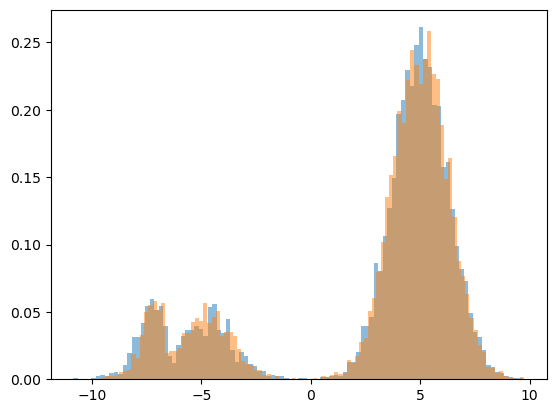

In [7]:
import matplotlib.pyplot as plt
plt.hist(X_rs_temp_0p33[0, :, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p005[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p05[:, 0], bins = 100, density=True, alpha=0.5)
plt.hist(X_temp_0p33_delta_0p1[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p2[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p3[:, 0], bins = 100, density=True, alpha=0.5)
plt.show()

In [8]:
lcb = LCB(
    2, 
    value_estimator_temp_1p0,
    core,
    delta = 0.1,
    fix_lambda=True,
    symmetric= True,
    lambda_value=1,
    lam_min=1,
    lam_max=2,
    erm_error=0.0,
    baseline_lr = 1e-4
)

model_temp_1p0 = LCBModel(core, lcb)
model_temp_1p0.num_train_steps_per_t = 200
model_temp_1p0.num_baseline_epochs_per_step = 1
X = model_temp_1p0.train()

print("effective N = ", model_temp_1p0.num_steps/(7000*20))

Ns_temp1p0 = {}

model_temp_1p0_delta_0p005 = model_temp_1p0
model_temp_1p0_delta_0p005.lcb.lam_max = 20
model_temp_1p0_delta_0p005.lcb.fix_lambda = False
model_temp_1p0_delta_0p005.lcb.delta = 0.005

model_temp_1p0_delta_0p005.num_train_steps_per_t = 1
model_temp_1p0_delta_0p005.num_steps = 0
X_temp_1p0_delta_0p005 = model_temp_1p0_delta_0p005.train()
print("effective N (temp=1.0, delta=0.005) = ", model_temp_1p0_delta_0p005.num_steps/(7000*20))
Ns_temp1p0["delta_0p005"] = model_temp_1p0_delta_0p005.num_steps/(7000*20)

model_temp_1p0_delta_0p05 = model_temp_1p0
model_temp_1p0_delta_0p05.lcb.lam_max = 10
model_temp_1p0_delta_0p05.lcb.fix_lambda = False
model_temp_1p0_delta_0p05.lcb.delta = 0.05

model_temp_1p0_delta_0p05.num_train_steps_per_t = 1
model_temp_1p0_delta_0p05.num_steps = 0
X_temp_1p0_delta_0p05 = model_temp_1p0_delta_0p05.train()
print("effective N (temp=1.0, delta=0.05) = ", model_temp_1p0_delta_0p05.num_steps/(7000*20))
Ns_temp1p0["delta_0p05"] = model_temp_1p0_delta_0p05.num_steps/(7000*20)

model_temp_1p0_delta_0p1 = model_temp_1p0
model_temp_1p0_delta_0p1.lcb.lam_max = 10
model_temp_1p0_delta_0p1.lcb.delta = 0.1
model_temp_1p0_delta_0p1.num_steps = 0
model_temp_1p0_delta_0p1.lcb.fix_lambda = False
model_temp_1p0_delta_0p1.num_train_steps_per_t = 1
X_temp_1p0_delta_0p1 = model_temp_1p0_delta_0p1.train()
print("effective N (temp=1.0, delta=0.1) = ", model_temp_1p0_delta_0p1.num_steps/(7000*20))
Ns_temp1p0["delta_0p1"] = model_temp_1p0_delta_0p1.num_steps/(7000*20)

model_temp_1p0_delta_0p2 = model_temp_1p0
model_temp_1p0_delta_0p2.lcb.lam_max = 10
model_temp_1p0_delta_0p2.lcb.fix_lambda = False
model_temp_1p0_delta_0p2.lcb.delta = 0.2

model_temp_1p0_delta_0p2.num_train_steps_per_t = 1
model_temp_1p0_delta_0p2.num_steps = 0
X_temp_1p0_delta_0p2 = model_temp_1p0_delta_0p2.train()
print("effective N (temp=1.0, delta=0.2) = ", model_temp_1p0_delta_0p2.num_steps/(7000*20))
Ns_temp1p0["delta_0p2"] = model_temp_1p0_delta_0p2.num_steps/(7000*20)

model_temp_1p0_delta_0p3 = model_temp_1p0
model_temp_1p0_delta_0p3.lcb.lam_max = 10
model_temp_1p0_delta_0p3.lcb.fix_lambda = False
model_temp_1p0_delta_0p3.lcb.delta = 0.3

model_temp_1p0_delta_0p3.num_train_steps_per_t = 1
model_temp_1p0_delta_0p3.num_steps = 0
X_temp_1p0_delta_0p3 = model_temp_1p0_delta_0p3.train()
print("effective N (temp=1.0, delta=0.3) = ", model_temp_1p0_delta_0p3.num_steps/(7000*20))
Ns_temp1p0["delta_0p3"] = model_temp_1p0_delta_0p3.num_steps/(7000*20)

LCB Model has S =  7000
effective N =  9.006742857142857
effective N (temp=1.0, delta=0.005) =  1.1776428571428572
effective N (temp=1.0, delta=0.05) =  1.216942857142857
effective N (temp=1.0, delta=0.1) =  1.1312785714285714
effective N (temp=1.0, delta=0.2) =  1.05955
effective N (temp=1.0, delta=0.3) =  1.0192857142857144


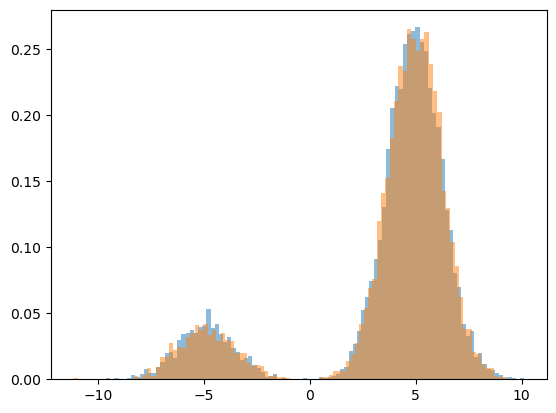

In [9]:
import matplotlib.pyplot as plt
plt.hist(X_rs_temp_1p0[0, :, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_1p0_delta_0p005[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p05[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p1[:, 0], bins = 100, density=True, alpha=0.5)
# plt.hist(X_temp_0p33_delta_0p2[:, 0], bins = 100, density=True, alpha=0.5)
plt.hist(X_temp_1p0_delta_0p1[:, 0], bins = 100, density=True, alpha=0.5)
plt.show()

In [ ]:
from animate_2d import animate_val_predictions
alpha_str = str(alpha).replace(".", "p")
animate_val_predictions(states, index_set, lcb, outfile=f"{run_dir}/lcb_{alpha_str}_SYM.gif")


Predictions shape: (20, 2500)
Value prediction range: -13.815511 0.41842315


'toy_data_runs/20260122_202321_157606/lcb_0p2_SYM.gif'

In [10]:
Ns_temp0p2, Ns_temp0p33, Ns_temp1p0

({'delta_0p005': 7.2240142857142855,
  'delta_0p05': 6.474407142857143,
  'delta_0p1': 5.516228571428571,
  'delta_0p2': 4.075342857142857,
  'delta_0p3': 3.286057142857143},
 {'delta_0p005': 3.982792857142857,
  'delta_0p05': 2.503942857142857,
  'delta_0p1': 2.092214285714286,
  'delta_0p2': 1.7038142857142857,
  'delta_0p3': 1.545907142857143},
 {'delta_0p005': 1.1776428571428572,
  'delta_0p05': 1.216942857142857,
  'delta_0p1': 1.1312785714285714,
  'delta_0p2': 1.05955,
  'delta_0p3': 1.0192857142857144})

In [15]:
import pickle
import os

# Define the data structure to save all samples and effective N values
data = {
    'temp_0.2': {
        'rs_samples': X_rs_temp_0p2,
        'rs_effective_N': rs_temp_0p2.num_steps / (7000 * 20),
        'lcb_delta_0.005': {
            'samples': X_temp_0p2_delta_0p005,
            'effective_N': Ns_temp0p2["delta_0p005"]
        },
        'lcb_delta_0.05': {
            'samples': X_temp_0p2_delta_0p05,
            'effective_N': Ns_temp0p2["delta_0p05"]
        },
        'lcb_delta_0.1': {
            'samples': X_temp_0p2_delta_0p1,
            'effective_N': Ns_temp0p2["delta_0p1"]
        },
        'lcb_delta_0.2': {
            'samples': X_temp_0p2_delta_0p2,
            'effective_N': Ns_temp0p2["delta_0p2"]
        },
        'lcb_delta_0.3': {
            'samples': X_temp_0p2_delta_0p3,
            'effective_N': Ns_temp0p2["delta_0p3"]
        }
    },
    'temp_0.33': {
        'rs_samples': X_rs_temp_0p33,
        'rs_effective_N': rs_temp_0p33.num_steps / (7000 * 20),
        'lcb_delta_0.005': {
            'samples': X_temp_0p33_delta_0p005,
            'effective_N': Ns_temp0p33["delta_0p005"]
        },
        'lcb_delta_0.05': {
            'samples': X_temp_0p33_delta_0p05,
            'effective_N': Ns_temp0p33["delta_0p05"]
        },
        'lcb_delta_0.1': {
            'samples': X_temp_0p33_delta_0p1,
            'effective_N': Ns_temp0p33["delta_0p1"]
        },
        'lcb_delta_0.2': {
            'samples': X_temp_0p33_delta_0p2,
            'effective_N': Ns_temp0p33["delta_0p2"]
        },
        'lcb_delta_0.3': {
            'samples': X_temp_0p33_delta_0p3,
            'effective_N': Ns_temp0p33["delta_0p3"]
        }
    },
    'temp_1.0': {
        'rs_samples': X_rs_temp_1p0,
        'rs_effective_N': rs_temp_1p0.num_steps / (7000 * 20),
        'lcb_delta_0.005': {
            'samples': X_temp_1p0_delta_0p005,
            'effective_N': Ns_temp1p0["delta_0p005"]
        },
        'lcb_delta_0.05': {
            'samples': X_temp_1p0_delta_0p05,
            'effective_N': Ns_temp1p0["delta_0p05"]
        },
        'lcb_delta_0.1': {
            'samples': X_temp_1p0_delta_0p1,
            'effective_N': Ns_temp1p0["delta_0p1"]
        },
        'lcb_delta_0.2': {
            'samples': X_temp_1p0_delta_0p2,
            'effective_N': Ns_temp1p0["delta_0p2"]
        },
        'lcb_delta_0.3': {
            'samples': X_temp_1p0_delta_0p3,
            'effective_N': Ns_temp1p0["delta_0p3"]
        }
    }
}

# Save the data to a pickle file in the run directory
output_file = os.path.join(run_dir, 'lcb_and_rs_results_20_value_epochs.pkl')
with open(output_file, 'wb') as f:
    pickle.dump(data, f)

print(f"All results saved to {output_file}")

All results saved to toy_data_runs/20260122_202321_157606/lcb_and_rs_results_20_value_epochs.pkl


In [16]:
data["temp_0.2"]["lcb_delta_0.1"]["effective_N"]

5.516228571428571

In [70]:
X_unguided_N[0, :, :].reshape(S, N, 2).shape

(7000, 3, 2)

In [ ]:
# from mixture_lower import Mixture
def reward_func_hard(x):
    x0 = np.asarray(x)[..., 0]
    return np.where(x0 < -7, 1, 0)
# # Best-of-N
# mu_0 = np.array([[5, 0], [-5, 0]])
# var_0 = np.eye(d)
# pi_0 = np.array([0.95, 0.05])
# pi_0 /= np.sum(pi_0)
# dist0 = Mixture(mu_0, var_0, pi_0)
S = 7000
# BoN_Ns = [1, 3, 5, 8, 10, 30, 35, 40]
BoN_Ns = [45]

# BoN_Ns = [60, 70]
# BoN_sets = {}
for N in BoN_Ns:
    print("N = ", N)
    core.S = N*S
    X_unguided_N= core.collect_run()
    X_N_candidates = X_unguided_N[0, :, :].reshape(S, N, 2)
    rewards = (reward_func_hard(X_N_candidates))
    best_indices = np.argmax(rewards, axis=1)
    X_best = X_N_candidates[np.arange(S), best_indices, :]
    BoN_sets[N] = (X_best)
# unguided_num_steps = 


N =  1
N =  3
N =  5
N =  8
N =  10
N =  30
N =  35
N =  40


In [28]:
Ns_temp0p2["delta_0p005"]

7.2240142857142855

In [40]:
import numpy as np

# Define the good reward region: x0 < -7
good_region_threshold = -7

N =40
# For BoN (Best-of-N) with N=40
bon_samples = BoN_sets[N]  # Shape: (7000, 2)
bon_mass_good = np.mean(bon_samples[:, 0] < good_region_threshold)
print(f"BoN (N=N) mass in good region (x0 < {good_region_threshold}): {bon_mass_good:.4f}")

# For Rejection Sampling (temp=0.2)
rs_samples = X_rs_temp_0p2[0, :, :]  # Shape: (7000, 2)
rs_mass_good = np.mean(rs_samples[:, 0] < good_region_threshold)
print(f"RS (temp=0.2) mass in good region (x0 < {good_region_threshold}): {rs_mass_good:.4f}")

delta = 0.3
lcb_samples = X_temp_0p2_delta_0p1
lcb_good = np.mean(lcb_samples[:, 0] < good_region_threshold)
print(f"LCB (temp=0.2) mass in good region (x0 < {good_region_threshold}): {lcb_good:.4f}")
# Comparison
print(f"Difference (BoN - RS): {bon_mass_good - rs_mass_good:.4f}")

BoN (N=N) mass in good region (x0 < -7): 0.2627
RS (temp=0.2) mass in good region (x0 < -7): 0.3071
LCB (temp=0.2) mass in good region (x0 < -7): 0.2986
Difference (BoN - RS): -0.0444


(array([0.00139627, 0.        , 0.00139627, 0.00279254, 0.00488694,
        0.01117015, 0.01186828, 0.02722723, 0.03001977, 0.06003954,
        0.08936118, 0.13823057, 0.1940813 , 0.22340294, 0.25272458,
        0.2471395 , 0.1347399 , 0.03211417, 0.00698134, 0.00698134,
        0.00767948, 0.01256642, 0.02164216, 0.02373656, 0.02303843,
        0.03979365, 0.03211417, 0.03979365, 0.03700111, 0.04049178,
        0.03351044, 0.03769925, 0.03281231, 0.03211417, 0.02234029,
        0.0244347 , 0.01745335, 0.01396268, 0.00977388, 0.01047201,
        0.00418881, 0.00488694, 0.0020944 , 0.0020944 , 0.00139627,
        0.00349067, 0.00069813, 0.        , 0.        , 0.00069813,
        0.        , 0.        , 0.        , 0.        , 0.00139627,
        0.00069813, 0.00069813, 0.0020944 , 0.00698134, 0.00349067,
        0.00698134, 0.01326455, 0.02583096, 0.02024589, 0.03769925,
        0.04677499, 0.06213394, 0.057247  , 0.07400222, 0.10890893,
        0.12287162, 0.12915482, 0.15428766, 0.16

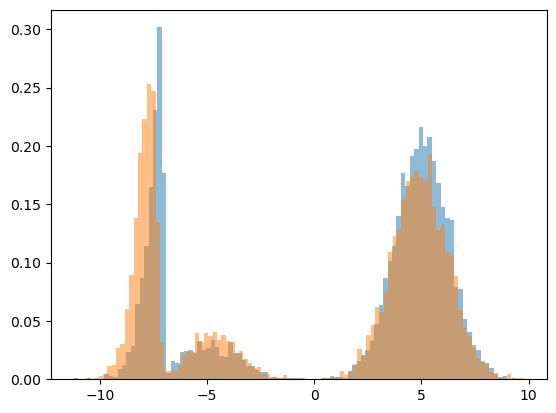

In [17]:
plt.hist(BoN_sets[40][:, 0], bins = 100, density=True, alpha=0.5)
plt.hist(X_rs_temp_0p2[0, :, 0], bins = 100, density=True, alpha=0.5)

In [29]:
import numpy as np

# Define the good reward region: x0 < -7
good_region_threshold = -7

N = 8
# For BoN (Best-of-N) with N=40
bon_samples = BoN_sets[N]  # Shape: (7000, 2)
bon_mass_good = np.mean(bon_samples[:, 0] < good_region_threshold)
print(f"BoN (N={N}) mass in good region (x0 < {good_region_threshold}): {bon_mass_good:.4f}")

# For Rejection Sampling (temp=0.2)
rs_samples = X_rs_temp_0p33[0, :, :]  # Shape: (7000, 2)
rs_mass_good = np.mean(rs_samples[:, 0] < good_region_threshold)
print(f"RS (temp=0.2) mass in good region (x0 < {good_region_threshold}): {rs_mass_good:.4f}")

# Comparison
print(f"Difference (BoN - RS): {bon_mass_good - rs_mass_good:.4f}")

BoN (N=8) mass in good region (x0 < -7): 0.0597
RS (temp=0.2) mass in good region (x0 < -7): 0.0607
Difference (BoN - RS): -0.0010


In [ ]:
import numpy as np

# Define the good reward region: x0 < -7
good_region_threshold = -7

N = 1
# For BoN (Best-of-N) with N=40
bon_samples = BoN_sets[N]  # Shape: (7000, 2)
bon_mass_good = np.mean(bon_samples[:, 0] < good_region_threshold)
print(f"BoN (N={N}) mass in good region (x0 < {good_region_threshold}): {bon_mass_good:.4f}")

# For Rejection Sampling (temp=0.2)
rs_samples = X_rs_temp_1p0[0, :, :]  # Shape: (7000, 2)
rs_mass_good = np.mean(rs_samples[:, 0] < good_region_threshold)
print(f"RS (temp=1.0) mass in good region (x0 < {good_region_threshold}): {rs_mass_good:.4f}")

# rs_mass_good = np.mean(rs_samples[:, 0] < good_region_threshold)
# print(f"LC (temp=1.0) mass in good region (x0 < {good_region_threshold}): {rs_mass_good:.4f}")
# Comparison
print(f"Difference (BoN - RS): {bon_mass_good - rs_mass_good:.4f}")

BoN (N=1) mass in good region (x0 < -7): 0.0083
RS (temp=1.0) mass in good region (x0 < -7): 0.0096
Difference (BoN - RS): -0.0013


In [38]:
import pickle
import os

# Save BoN_sets to a pickle file
bon_output_file = os.path.join(run_dir, 'bon_results.pkl')
with open(bon_output_file, 'wb') as f:
    pickle.dump(BoN_sets, f)

print(f"BoN results saved to {bon_output_file}")

BoN results saved to toy_data_runs/20260122_202321_157606/bon_results.pkl


In [51]:
import numpy as np

class FinalRejectionSampling:
    """
    Rejection sampling applied only at the final step: rollout full diffusion trajectories,
    evaluate reward r(x_0) for the clean state, and accept the entire trajectory with
    probability exp(r(x_0)) / exp(1/alpha), where alpha is the temperature.
    """
    def __init__(self, core, alpha: float, N: int = 5):
        self.core = core
        self.core.reset()
        self.alpha = alpha
        self.Z = np.exp(1 / alpha)  # normalizing constant
        self.N = int(N)
        self.S = self.core.S
        self.num_steps = 0  # total proposals (trajectories generated)

    def set_S(self, S: int):
        self.core.S = int(S)
        self.S = int(S)
        self.core.reset()

    def calc_samples(self):
        """
        Generate samples by accepting/rejecting full trajectories based on final reward.
        Returns array of shape (S, d) of noiseless accepted states.
        """
        self.core.reset()
        self.num_steps = 0

        accepted_states = []

        while len(accepted_states) < self.S:
            # Generate N trajectories
            self.core.S = self.N
            X_full = self.core.collect_run()  # (T+1, N, d)

            x0s = X_full[0, :, :]  # (N, d)
            rewards = reward_func_hard(x0s)/self.alpha
            probs = np.exp(rewards) / self.Z  # acceptance probabilities

            u = np.random.rand(self.N)
            accept_mask = u < probs

            # Collect accepted states: list of (d,)
            for i in np.where(accept_mask)[0]:
                accepted_states.append(x0s[i])

            self.num_steps += self.N

        # Stack to (S, d)
        accepted_states = np.stack(accepted_states[:self.S], axis=0)
        return accepted_states


frs_temp_0p2 = FinalRejectionSampling(core=core, alpha=0.2, N=5)
frs_temp_0p2.set_S(7000)
X_frs_temp_0p2 = frs_temp_0p2.calc_samples()
print("proposal per accepted sample ratio (final RS, temp=0.2):", frs_temp_0p2.num_steps / 7000)

frs_temp_0p33 = FinalRejectionSampling(core=core, alpha=0.33, N=5)
frs_temp_0p33.set_S(7000)
X_frs_temp_0p33 = frs_temp_0p33.calc_samples()
print("proposal per accepted sample ratio (final RS, temp=0.33):", frs_temp_0p33.num_steps / 7000)

frs_temp_1p0 = FinalRejectionSampling(core=core, alpha=1.0, N=5)
frs_temp_1p0.set_S(7000)
X_frs_temp_1p0 = frs_temp_1p0.calc_samples()
print("proposal per accepted sample ratio (final RS, temp=1.0):", frs_temp_1p0.num_steps / 7000)

proposal per accepted sample ratio (final RS, temp=0.2): 70.94642857142857
proposal per accepted sample ratio (final RS, temp=1.0): 2.6864285714285714


In [53]:
import pickle
import os

# Define the data structure for final rejection sampling
final_rs_data = {
    'temp_0.2': {
        'samples': X_frs_temp_0p2,
        'effective_N': frs_temp_0p2.num_steps / 7000
    },
    'temp_0.33': {
        'samples': X_frs_temp_0p33,
        'effective_N': frs_temp_0p33.num_steps / 7000
    },
    'temp_1.0': {
        'samples': X_frs_temp_1p0,
        'effective_N': frs_temp_1p0.num_steps / 7000
    }
}

# Save the data to a pickle file in the run directory
final_rs_output_file = os.path.join(run_dir, 'true_distribution_results.pkl')
with open(final_rs_output_file, 'wb') as f:
    pickle.dump(final_rs_data, f)

print(f"Final rejection sampling results saved to {final_rs_output_file}")

Final rejection sampling results saved to toy_data_runs/20260122_202321_157606/true_distribution_results.pkl


(array([  1.,   1.,   2.,   6.,   5.,   9.,  14.,  17.,  28.,  60., 100.,
        151., 226., 309., 472., 653., 881., 780.,  10.,   9.,  17.,  25.,
         23.,  27.,  29.,  22.,  30.,  26.,  30.,  25.,  27.,  22.,  20.,
         25.,  16.,  17.,  10.,  13.,  12.,   6.,   2.,   2.,   3.,   3.,
          5.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   2.,
          1.,   3.,   1.,   3.,   1.,   7.,  10.,  23.,  24.,  21.,  56.,
         47.,  64.,  83.,  81., 105., 126., 155., 152., 197., 145., 186.,
        167., 165., 156., 138., 132., 120., 118.,  82.,  66.,  63.,  38.,
         26.,  22.,  24.,   8.,   5.,   2.,   0.,   0.,   2.,   1.,   0.,
          1.]),
 array([-1.06266582e+01, -1.04222591e+01, -1.02178600e+01, -1.00134610e+01,
        -9.80906187e+00, -9.60466278e+00, -9.40026370e+00, -9.19586461e+00,
        -8.99146552e+00, -8.78706643e+00, -8.58266734e+00, -8.37826825e+00,
        -8.17386917e+00, -7.96947008e+00, -7.76507099e+00, -7.56067190e+00,
        -7.356

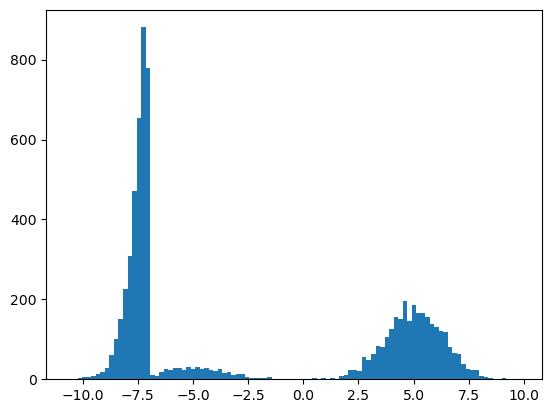

In [52]:
plt.hist(X_frs_temp_0p2[:, 0], bins = 100)

In [54]:
X_throwaway = model_temp_0p2_delta_0p1.calc_samples()

In [55]:
X_throwaway.shape

(20, 7000, 2)

In [38]:
lcb = LCB.load_lcb(run_dir, run_id, value_estimator_temp_0p2, core, 0.2, sym_str = "SYM", name = "lambda_fixed_1_source")
model_temp_0p2 = LCBModel(core, lcb)
model_temp_0p2.set_S(7000)
model_temp_0p2_delta_0p1 = model_temp_0p2
model_temp_0p2_delta_0p1.lcb.lam_max = 10
model_temp_0p2_delta_0p1.lcb.delta = 0.1
model_temp_0p2_delta_0p1.num_steps = 0
model_temp_0p2_delta_0p1.lcb.fix_lambda = False
model_temp_0p2_delta_0p1.num_train_steps_per_t = 1
X_temp_0p2_delta_0p1 = model_temp_0p2_delta_0p1.train()

LCB Model has S =  7000


In [39]:
model_temp_0p2_delta_0p1.num_steps/(7000*20)

6.373257142857143

In [ ]:
T = 20 
def reward_func_hard(x):
    x0 = np.asarray(x)[..., 0]
    return np.where(x0 < -7, 1, 0)




S = 7000

# BoN_Ns_lcb = [1, 3, 5, 7, 10]
# BoN_Ns_lcb = [2, 3, 4, 5, 7, 10]
BoN_Ns_lcb = [2, 3]
BoN_sets_lcb = {}
for N in BoN_Ns_lcb:
    print("N = ", N)
    model_temp_0p2_delta_0p1.set_S(N*S)
    model_temp_0p2_delta_0p1.num_steps = 0
    X_N_candidates = model_temp_0p2_delta_0p1.calc_samples()[0, :, :].reshape(S, N, 2)
    rewards = (reward_func_hard(X_N_candidates))
    best_indices = np.argmax(rewards, axis=1)
    X_best = X_N_candidates[np.arange(S), best_indices, :]
    BoN_sets_lcb[N] = {"samples": X_best, "eff N": model_temp_0p2_delta_0p1.num_steps/(S*T)}
# unguided_num_steps = 


N =  3
N =  4
N =  5


In [91]:
import pickle
import os

# Save BoN_sets_lcb to a pickle file
lcb_plus_bon_output_file = os.path.join(run_dir, 'lcb_plus_BoN.pkl')
with open(lcb_plus_bon_output_file, 'wb') as f:
    pickle.dump(BoN_sets_lcb, f)

print(f"LCB plus BoN results saved to {lcb_plus_bon_output_file}")

LCB plus BoN results saved to toy_data_runs/20260122_202321_157606/lcb_plus_BoN.pkl


In [88]:
BoN_sets_lcb

{3: {'samples': array([[-8.53067223,  2.31999803],
         [-7.36071443, -2.35927361],
         [ 4.26876244, -1.1086246 ],
         ...,
         [-7.89755472, -1.05074424],
         [-7.61857091,  0.23203892],
         [ 6.56830998, -0.85193978]]),
  'eff N': 10.136364285714286}}

(array([  5.,   1.,   9.,   6.,  15.,  26.,  66.,  78., 114., 198., 285.,
        459., 673., 822., 598., 216.,  27.,   9.,   5.,   7.,  18.,  27.,
         24.,  35.,  34.,  33.,  53.,  34.,  34.,  47.,  41.,  20.,  21.,
         34.,  25.,  24.,  15.,  19.,   7.,   5.,   7.,   5.,   5.,   1.,
          0.,   0.,   2.,   1.,   0.,   1.,   0.,   0.,   1.,   0.,   1.,
          0.,   1.,   1.,   4.,   5.,   6.,   4.,  10.,   8.,  19.,  21.,
         33.,  40.,  44.,  55.,  77., 104., 108., 111., 139., 131., 161.,
        149., 159., 158., 174., 156., 146., 110., 126.,  98.,  92.,  87.,
         65.,  49.,  40.,  39.,  22.,  19.,  11.,   5.,   8.,   5.,   1.,
          6.]),
 array([-10.0822409 ,  -9.89248827,  -9.70273563,  -9.512983  ,
         -9.32323036,  -9.13347773,  -8.94372509,  -8.75397246,
         -8.56421982,  -8.37446719,  -8.18471455,  -7.99496192,
         -7.80520928,  -7.61545665,  -7.42570401,  -7.23595138,
         -7.04619875,  -6.85644611,  -6.66669348,  -6.47694084

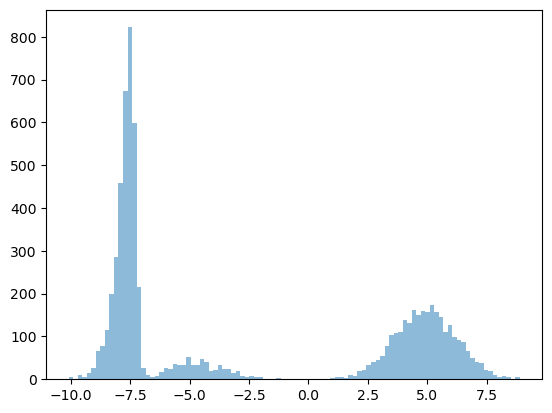

In [ ]:
plt.hist(BoN_sets_lcb[3]["samples"][:, 0], bins = 100, alpha=0.5)